# 07 Eindmodel: 3 tot 5 onderbouwde leesadviezen

Dit notebook laat het eindresultaat zien zoals de opdracht vraagt:

1. het **studentprofiel analyseren** (interesses, leesniveau, voorkeuren),
2. het leesmateriaal **vergelijken** met het profiel,
3. **3 tot 5** gepersonaliseerde aanbevelingen,
4. **uitleg**: waarom past dit bij de student?

Daarna trainen we het eindmodel op alle data en slaan het op voor de API.

In [1]:
import sys
from pathlib import Path

# Make the project package importable, also without "pip install -e ."
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from leescoach import config

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
from leescoach.data_cleaning import load_processed
from leescoach.features import StudentProfile
from leescoach.hybrid import HybridRecommender

materials, students, interactions = load_processed()
model = HybridRecommender().fit(materials, students, interactions)
path = model.save()
print("Model opgeslagen in", path)

Model opgeslagen in C:\Users\jesse\Desktop\Avans\2.1 Full-Stack Web Applications With AI\smart-reading-coach-ai\models\hybride_model.joblib


## 1. Een student uit de dataset

In [3]:
def show_advice(student_id: str, n: int = 5) -> None:
    student = students.set_index("student_id").loc[student_id]
    profile = StudentProfile.from_dataset_row(students[students["student_id"] == student_id].iloc[0])
    own = interactions[interactions["student_id"] == student_id]
    history = dict(zip(own["cataloguscode"], own["voorkeurscore"]))
    print(f"Student {student_id}: niveau {student['leesniveau']}, taal {student['taalniveau']}, interesses {student['interesses'].replace(';', ', ')}")
    print(f"Voorkeur {student['voorkeur_materiaaltype']}, genre {student['voorkeur_genre']}, max {student['max_leestijd_min']} minuten,"
          f" {int(own['positief'].sum())} van {len(own)} eerdere interacties positief")
    print()
    for number, item in enumerate(model.recommend(profile, history, n=n), start=1):
        print(f"{number}. {item.titel} ({item.type}, {item.niveau}), score {item.score:.2f}")
        for reason in item.redenen:
            print(f"     * {reason}")
    print()

for student_id in ["S001", "S004", "S042"]:
    show_advice(student_id)

Student S001: niveau 2F, taal C1, interesses kunstmatige intelligentie, relaties
Voorkeur boek, genre informatief, max 60 minuten, 7 van 20 eerdere interacties positief

1. Wat is een rechtsstaat? (online-artikel, 2F-3F), score 0.87
     * Het niveau (2F-3F) is net iets uitdagender dan jouw niveau (2F), goed om te groeien.
     * Het genre (informatief) is jouw voorkeur.
     * De leestijd is ongeveer 10 minuten, dat past binnen jouw 60 minuten.
2. De fout (boek, 2F), score 0.87
     * Het gaat over relaties, iets waar je interesse in hebt.
     * Het niveau (2F) past precies bij jouw leesniveau (2F).
     * Studenten met een vergelijkbare smaak waardeerden dit hoog.
     * Het is een boek, dat is het soort materiaal dat je graag leest.
3. Een echte man (boek, 2F), score 0.87
     * Het gaat over relaties, iets waar je interesse in hebt.
     * Het niveau (2F) past precies bij jouw leesniveau (2F).
     * Het is een boek, dat is het soort materiaal dat je graag leest.
     * Het is lan

## 2. Een nieuwe student zonder geschiedenis (cold start)
Zo komt een profiel uit de Fastify app binnen. Zonder geschiedenis leunt het model op inhoud en profiel.

In [4]:
new_student = StudentProfile(
    leesniveau="2F",
    interesses=["sport", "vriendschap", "humor"],
    materiaaltypes=["boek"],
    voorkeur_genre="fictie",
    max_leestijd_min=90,
)
for item in model.recommend(new_student, n=3):
    print(f"{item.titel} ({item.niveau}): {item.samenvatting}")

Naar de haaien (2F): Het gaat over humor, iets waar je interesse in hebt.
Imke (2F): Het gaat over humor, iets waar je interesse in hebt.
De open era (2F-3F): Het gaat over sport, iets waar je interesse in hebt.


## 3. Het advies verandert met de geschiedenis
De student leest en waardeert het eerste advies. Daarna schuift het advies op.

In [5]:
first = model.recommend(new_student, n=5)
history = {first[0].cataloguscode: 5.0, first[1].cataloguscode: 1.0}
print("Gelezen en leuk:", first[0].titel, "| afgewezen:", first[1].titel)
for item in model.recommend(new_student, history, n=5):
    print(f"  {item.titel} ({item.score:.2f})")

Gelezen en leuk: Naar de haaien | afgewezen: Imke
  Een echte man (0.92)
  De deal (0.91)
  De roadtrip (0.91)
  Fake Skating (0.90)
  PIEN 2 (0.91)


## 4. Wat ziet de docent?
Voor transparantie kan de docent per advies de onderliggende kenmerken zien, en welke signalen in het algemeen het zwaarst wegen.

In [6]:
item = model.recommend(new_student, n=1)[0]
from leescoach.features import FEATURE_LABELS
pd.Series(item.kenmerken).rename(index=FEATURE_LABELS).to_frame(item.titel)

,Naar de haaien
Niveauverschil (materiaal min student),0.0000
Afstand tot eigen niveau,0.0000
Past bij voorkeur materiaaltype,1.0000
Past bij voorkeur genre,1.0000
Tekstovereenkomst met interesses,0.0944
Aantal interesses in de tekst,1.0000
Lijkt op eerder gewaardeerd materiaal,0.0000
Leestijd ten opzichte van maximum (log),1.2238
Binnen maximale leestijd,0.0000
Juiste taal,1.0000


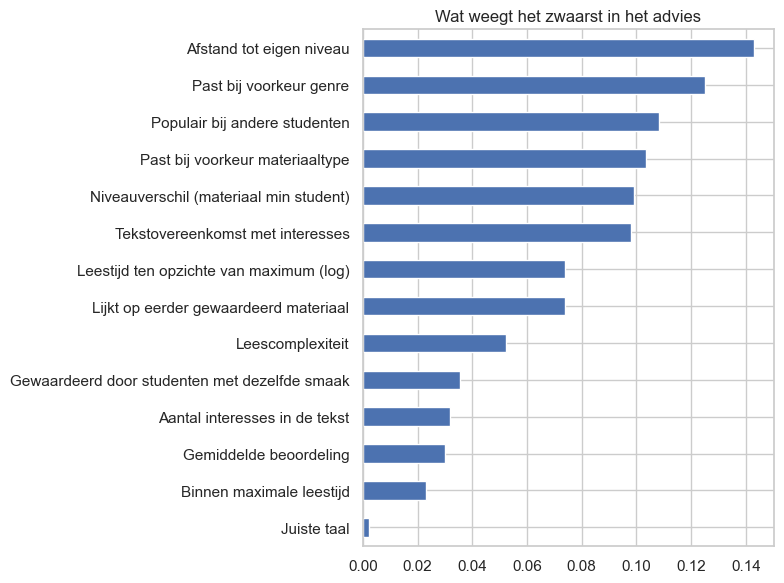

In [7]:
model.feature_importance.rename(index=FEATURE_LABELS).plot.barh(figsize=(8, 6), title="Wat weegt het zwaarst in het advies")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Volgende stap: koppelen aan de app

Start de API (`uvicorn api.main:app --port 8000`) en laat de Fastify backend `POST /api/recommendations` aanroepen met het
leesprofiel en de leeslijst van de student. Zie `docs/koppeling-fastify.md`.